<a href="https://colab.research.google.com/github/Bunkhuoch-Ann/Side_Quests_simple/blob/main/Gold_Pred.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Training and saving the model

In [1]:
!pip install python-binance
%pip install --no-cache-dir -U curl_cffi yfinance
!pip install -q ipympl
%pip install reproject
!pip install mplcursors
#================================"Important"=====================================
#After running this cell please restart the session then continue from the next cell
#================================================================================

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [python-binance]
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.66
    Uninstalling yfinance-0.2.66:
      Successfully uninstalled yfinance-0.2.66
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 64.3 MB/s  0:00:00
  Created wheel for pims: filename=pims-0.7-py3-none-any.whl size=84644 sha256=6d1c12ea4b58580b87ddf2bbbbe56f84bbf04079c930cf4683e2fcc327defcca
  Stored in directory: /root/.cache/pip/wheels/9b/9e/a8/a0f41cf12a4a7b98a501ad8590595e2071a946d2fd33b0eb60
Successfully built pims
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [reproject]


In [1]:
import os

os.environ["YF_DISABLE_CURL_CFFI"] = "1"

import yfinance as yf
import requests
import pandas as pd

print("Using standard requests:", requests.__version__)

Using standard requests: 2.32.4


In [2]:
# User selects a currency pair
import joblib
import os
import numpy as np
import pandas as pd
import requests
from datetime import datetime, timedelta
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt
# import swing_technical_indicators
from binance.client import Client
from binance.enums import *
import pandas as pd
import datetime as dt
import time
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.preprocessing import MinMaxScaler

def deseasonalize_column(data, column, period=7):
    # Decompose the column
    decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')

    # Extract the residual component as deseasonalized data
    deseasonalized = data[column] - decomposition.seasonal

    return deseasonalized

def create_train_sequences(X, y, dates, seq_len=24, horizon=6):
    X_seq, y_seq, d_seq = [], [], []

    for i in range(len(X) - seq_len - horizon + 1):
        X_seq.append(X[i:i+seq_len])
        y_seq.append(y[i+seq_len:i+seq_len+horizon])
        d_seq.append(dates[i+seq_len+horizon-1])

    return np.array(X_seq), np.array(y_seq), np.array(d_seq)

def create_live_sequence(X, seq_len=50):
    """
    X = scaled feature dataframe (latest data)
    Returns the LAST sequence only
    """
    if len(X) < seq_len:
        raise ValueError("Not enough data to build sequence")

    X_last = X[-seq_len:]           # last 21 days
    return X_last.reshape(1, -1)    # flatten for MLP


In [3]:
#I credit this indicator to 'Sejal Hanmante','Shivani Patil','Uzma patil' authors of the paper:
#============'A library for calculating technical indicators for swing trading'================
#==============================================================================================
#================= edited for the compatibility to this work by Bunkhuoch Ann =================
#==============================================================================================
import pandas as pd
import  numpy as np

import numpy as np
import pandas as pd

def calculate_rsi(data: pd.DataFrame, column_name: str = 'Closing_price', period: int = 14) -> pd.Series:
    """
    Calculate the Relative Strength Index (RSI) for a given DataFrame.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - column_name (str): The name of the column to calculate RSI on (default is 'Closing_price').
    - period (int): The number of periods to use for RSI calculation (default is 14).

    Returns:
    - pd.Series: A Pandas Series containing the RSI values.
    """

    # Ensure the column exists
    if column_name not in data.columns:
        raise ValueError(f"Column '{column_name}' does not exist in the DataFrame.")

    # Step 1: Calculate the daily change in the specified column (e.g., Closing Price)
    delta = data[column_name].diff()

    # Step 2: Calculate Gain and Loss
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)

    # Step 3: Create a DataFrame for Gain and Loss
    # gain_df = pd.DataFrame(gain, columns=['Gain'])
    # loss_df = pd.DataFrame(loss, columns=['Loss'])
    gain_df = pd.DataFrame(gain, index=data.index, columns=['Gain'])
    loss_df = pd.DataFrame(loss, index=data.index, columns=['Loss'])

    # Step 4: Calculate the rolling average gain and loss
    avg_gain = gain_df['Gain'].rolling(window=period, min_periods=period).mean()
    avg_loss = loss_df['Loss'].rolling(window=period, min_periods=period).mean()

    # Step 5: Calculate the Relative Strength (RS)
    rs = avg_gain / avg_loss

    # Step 6: Calculate the RSI
    rsi = 100 - (100 / (1 + rs))

    # rsi = pd.Series(rsi, name=f"RSI_{period}").fillna(0)
    rsi = pd.Series(rsi, index=data.index, name=f"RSI_{period}").fillna(0)


    # Align the result with the input DataFrame


    return rsi

def calculate_200ema(data: pd.DataFrame, column_name: str = 'Closing_price', period: int = 200) -> pd.Series:
    """
    Calculate the Exponential Moving Average (EMA) for a given DataFrame.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - column_name (str): The name of the column to calculate EMA on (default is 'Closing_price').
    - period (int): The number of periods to use for EMA calculation (default is 200).

    Returns:
    - pd.Series: A Pandas Series containing the EMA values.
    """

    # Ensure the column exists
    if column_name not in data.columns:
        raise ValueError(f"Column '{column_name}' does not exist in the DataFrame.")

    # Calculate the EMA
    ema = data[column_name].ewm(span=period, adjust=False).mean()

    # Return the EMA as a Pandas Series
    return pd.Series(ema, name=f"EMA_{period}")

def calculate_swing_support_resistance(data: pd.DataFrame, timeframe: str = 'daily') -> pd.DataFrame:
    """
    Calculate Support and Resistance levels for Swing Trading using Pivot Points for the given timeframe.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - timeframe (str): The timeframe for pivot point calculation, either 'daily', 'weekly', or 'monthly'.

    Returns:
    - pd.DataFrame: DataFrame with Pivot Points, Support, and Resistance levels, forward filled for non-resampled rows.
    """
    # Ensure the 'Date' column is in datetime format and set it as the index
    data['Date'] = pd.to_datetime(data['Date'])
    data.set_index('Date', inplace=True)

    if timeframe == 'daily':
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    elif timeframe == 'weekly':
        # Resample for weekly data
        resampled_data = data.resample('W').agg({
            'Day_high': 'max',
            'Day_low': 'min',
            'Closing_price': 'last'
        })
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    elif timeframe == 'monthly':
        # Resample for monthly data
        resampled_data = data.resample('M').agg({
            'Day_high': 'max',
            'Day_low': 'min',
            'Closing_price': 'last'
        })
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    else:
        raise ValueError("Timeframe must be 'daily', 'weekly', or 'monthly'.")

    # Calculate Pivot Point, Support, and Resistance levels
    resampled_data['Pivot_Point'] = (resampled_data[high_col] + resampled_data[low_col] + resampled_data[close_col]) / 3
    resampled_data['Support_1'] = (2 * resampled_data['Pivot_Point']) - resampled_data[high_col]
    resampled_data['Resistance_1'] = (2 * resampled_data['Pivot_Point']) - resampled_data[low_col]
    resampled_data['Support_2'] = resampled_data['Pivot_Point'] - (resampled_data[high_col] - resampled_data[low_col])
    resampled_data['Resistance_2'] = resampled_data['Pivot_Point'] + (resampled_data[high_col] - resampled_data[low_col])

    # Forward fill the calculated levels for the original data
    resampled_data = resampled_data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']]
    data = data.join(resampled_data, how='outer')

    # Fill NaN values using forward fill and backward fill
    data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']] = data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']].ffill().bfill()

    # Reset the index for the final output
    data.reset_index(inplace=True)

    return data

def calculate_50ema(data: pd.DataFrame, column_name: str = 'Closing_price', period: int = 50) -> pd.Series:
    """
    Calculate the Exponential Moving Average (EMA) for a given DataFrame.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - column_name (str): The name of the column to calculate EMA on (default is 'Closing_price').
    - period (int): The number of periods to use for EMA calculation (default is 200).

    Returns:
    - pd.Series: A Pandas Series containing the EMA values.
    """

    # Ensure the column exists
    if column_name not in data.columns:
        raise ValueError(f"Column '{column_name}' does not exist in the DataFrame.")

    # Calculate the EMA
    ema = data[column_name].ewm(span=period, adjust=False).mean()

    # Return the EMA as a Pandas Series
    return pd.Series(ema, name=f"EMA_{period}")

def calculate_100ema(data: pd.DataFrame, column_name: str = 'Closing_price', period: int = 100) -> pd.Series:
    """
    Calculate the Exponential Moving Average (EMA) for a given DataFrame.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - column_name (str): The name of the column to calculate EMA on (default is 'Closing_price').
    - period (int): The number of periods to use for EMA calculation (default is 200).

    Returns:
    - pd.Series: A Pandas Series containing the EMA values.
    """

    # Ensure the column exists
    if column_name not in data.columns:
        raise ValueError(f"Column '{column_name}' does not exist in the DataFrame.")

    # Calculate the EMA
    ema = data[column_name].ewm(span=period, adjust=False).mean()

    # Return the EMA as a Pandas Series
    return pd.Series(ema, name=f"EMA_{period}")

def calculate_bollinger_bands(data, period=20, num_std_dev=2):
    ##Period 20 is ideal for swing traders
    sma = data.rolling(window=period).mean()
    std_dev = data.rolling(window=period).std()
    upper_band = sma + (std_dev * num_std_dev)
    lower_band = sma - (std_dev * num_std_dev)

    bands =  pd.DataFrame({
        'Price': data,
        'SMA': sma,
        'Upper Band': upper_band,
        'Lower Band': lower_band
    })

    bands.fillna(method='ffill', inplace=True)  # Forward-fill
    bands.fillna(method='bfill', inplace=True)  # Backward-fill

    return bands

import pandas as pd

def calculate_macd(data: pd.DataFrame, column_name: str = 'Closing_price', short_period: int = 12, long_period: int = 26, signal_period: int = 9) -> pd.DataFrame:
    """
    Calculate the Moving Average Convergence Divergence (MACD) and its Signal Line for a given DataFrame.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - column_name (str): The name of the column to calculate MACD on (default is 'Closing_price').
    - short_period (int): The short period for the fast EMA (default is 12).
    - long_period (int): The long period for the slow EMA (default is 26).
    - signal_period (int): The period for the Signal Line (default is 9).

    Returns:
    - pd.DataFrame: A DataFrame containing the MACD, Signal Line, and the MACD Histogram.
    """

    # Ensure the column exists
    if column_name not in data.columns:
        raise ValueError(f"Column '{column_name}' does not exist in the DataFrame.")

    # Calculate the short-term EMA (12-period)
    short_ema = data[column_name].ewm(span=short_period, adjust=False).mean()

    # Calculate the long-term EMA (26-period)
    long_ema = data[column_name].ewm(span=long_period, adjust=False).mean()

    # Calculate the MACD (difference between short-term and long-term EMAs)
    macd = short_ema - long_ema

    # Calculate the Signal Line (9-period EMA of the MACD)
    signal_line = macd.ewm(span=signal_period, adjust=False).mean()

    # Calculate the MACD Histogram (difference between MACD and Signal Line)
    macd_histogram = macd - signal_line

    # Create a DataFrame with the MACD, Signal Line, and Histogram
    macd_df = pd.DataFrame({
        'MACD': macd,
        'Signal_Line': signal_line,
        'MACD_Histogram': macd_histogram
    })

    return macd_df

def calculate_swing_support_resistance(data: pd.DataFrame, timeframe: str = 'daily') -> pd.DataFrame:
    """
    Calculate Support and Resistance levels for Swing Trading using Pivot Points for the given timeframe.

    Parameters:
    - data (pd.DataFrame): Input DataFrame containing the price data.
    - timeframe (str): The timeframe for pivot point calculation, either 'daily', 'weekly', or 'monthly'.

    Returns:
    - pd.DataFrame: DataFrame with Pivot Points, Support, and Resistance levels, forward filled for non-resampled rows.
    """
    # Ensure the 'Date' column is in datetime format and set it as the index
    data['Date'] = pd.to_datetime(data['Date'])
    data.set_index('Date', inplace=True)

    if timeframe == 'daily':
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    elif timeframe == 'weekly':
        # Resample for weekly data
        resampled_data = data.resample('W').agg({
            'Day_high': 'max',
            'Day_low': 'min',
            'Closing_price': 'last'
        })
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    elif timeframe == 'monthly':
        # Resample for monthly data
        resampled_data = data.resample('M').agg({
            'Day_high': 'max',
            'Day_low': 'min',
            'Closing_price': 'last'
        })
        high_col = 'Day_high'
        low_col = 'Day_low'
        close_col = 'Closing_price'
    else:
        raise ValueError("Timeframe must be 'daily', 'weekly', or 'monthly'.")

    # Calculate Pivot Point, Support, and Resistance levels
    resampled_data['Pivot_Point'] = (resampled_data[high_col] + resampled_data[low_col] + resampled_data[close_col]) / 3
    resampled_data['Support_1'] = (2 * resampled_data['Pivot_Point']) - resampled_data[high_col]
    resampled_data['Resistance_1'] = (2 * resampled_data['Pivot_Point']) - resampled_data[low_col]
    resampled_data['Support_2'] = resampled_data['Pivot_Point'] - (resampled_data[high_col] - resampled_data[low_col])
    resampled_data['Resistance_2'] = resampled_data['Pivot_Point'] + (resampled_data[high_col] - resampled_data[low_col])

    # Forward fill the calculated levels for the original data
    resampled_data = resampled_data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']]
    data = data.join(resampled_data, how='outer')

    # Fill NaN values using forward fill and backward fill
    data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']] = data[['Pivot_Point', 'Support_1', 'Resistance_1', 'Support_2', 'Resistance_2']].ffill().bfill()

    # Reset the index for the final output
    data.reset_index(inplace=True)

    return data

In [4]:
import yfinance as yf
import pandas as pd

ticker = "GC=F"  # Gold futures USD
symbol = "XAUUSD"

df = yf.download(ticker, start="1990-01-01", progress=True)

# Fix new yfinance column structure
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)

df.index = pd.to_datetime(df.index)

df_weekly = df.resample('W-FRI').agg({
    "Open": "first",
    "High": "max",
    "Low": "min",
    "Close": "last",
    "Volume": "sum"
})

df_weekly.dropna(inplace=True)
# df_weekly.to_csv("gold_usd_weekly.csv")
# Convert index → column
df_weekly = df_weekly.reset_index()   # 🔥 THIS is the missing step

# --- Keep only OHLC ---
df_clean = df_weekly[["Date", "Open", "High", "Low", "Close"]].copy()

# Ensure Date is datetime and sorted
df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Round prices
df_clean[["Open","High","Low","Close"]] = df_clean[["Open","High","Low","Close"]].round(2)

df_clean = df_clean.reset_index(drop=True)
df_clean.columns.name = None   # removes "Price"

# Save WITHOUT index
# df_clean.to_csv("XAUUSD1week.csv", index=False)

print("Clean file saved!")
print(df_clean.tail())

# print(df_weekly.tail())

[*********************100%***********************]  1 of 1 completed

Clean file saved!
           Date    Open    High     Low   Close
1364 2026-10-23  4185.0  4211.2  3989.1  4007.9
1365 2026-10-30  4012.2  4097.2  3879.3  3898.9
1366 2026-11-06  3890.0  4155.8  3889.0  4074.9
1367 2026-11-13  4074.3  4157.7  3856.7  3886.3
1368 2026-11-20  3869.7  3904.3  3694.5  3727.8


In [5]:
TIME_COL = "Date"
df_clean[TIME_COL] = pd.to_datetime(df_clean[TIME_COL])
df_clean = df_clean.sort_values(TIME_COL).set_index(TIME_COL)

START = "2000-01-01"
END   = "2026-11-18"
start = pd.to_datetime(START)
end   = pd.to_datetime(END)
all_data = df_clean.loc[START:END].copy()

In [6]:
all_data.tail()

,Open,High,Low,Close
Date,,,,
2026-10-16,4220.8,4242.3,4095.0,4181.1
2026-10-23,4185.0,4211.2,3989.1,4007.9
2026-10-30,4012.2,4097.2,3879.3,3898.9
2026-11-06,3890.0,4155.8,3889.0,4074.9
2026-11-13,4074.3,4157.7,3856.7,3886.3


In [7]:
# Identify non-stationary columns
non_stationary_columns = ['Open', 'High', 'Low', 'Close']

# Create deseasonalized columns
for col in non_stationary_columns:
    deseasonalized_col = deseasonalize_column(all_data, col, period=6)  # Adjust the period as needed
    all_data[f'Deseasonalized_{col}'] = deseasonalized_col

/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decompos

In [8]:
all_data["RSI"] = calculate_rsi(all_data, 'Close', 15).bfill().ffill()

macd_df = calculate_macd(all_data, column_name='Close')
all_data = pd.concat([all_data, macd_df], axis=1)
all_data[['MACD', 'Signal_Line', 'MACD_Histogram']] = \
    all_data[['MACD', 'Signal_Line', 'MACD_Histogram']].bfill().ffill()

bb = calculate_bollinger_bands(
    all_data['Close'], period=20, num_std_dev=2
)
all_data = pd.concat([all_data, bb], axis=1)

all_data['EMA_100'] = calculate_100ema(all_data, 'Close', 100).bfill().ffill()
all_data['EMA_200'] = calculate_200ema(all_data, 'Close', 200).bfill().ffill()
all_data['EMA_50'] = calculate_100ema(all_data, 'Close', 50).bfill().ffill()
all_data.index = pd.to_datetime(all_data.index)

all_data['hour'] = all_data.index.hour
all_data['day_of_week'] = all_data.index.dayofweek
all_data['month']       = all_data.index.month
all_data['is_weekend']  = (all_data.index.dayofweek >= 5).astype(int)

/tmp/ipykernel_3352/1686312986.py:205: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  bands.fillna(method='ffill', inplace=True)  # Forward-fill
/tmp/ipykernel_3352/1686312986.py:206: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  bands.fillna(method='bfill', inplace=True)  # Backward-fill


In [9]:
all_data.isnull().sum()

,0
Open,0
High,0
Low,0
Close,0
Deseasonalized_Open,0
Deseasonalized_High,0
Deseasonalized_Low,0
Deseasonalized_Close,0
RSI,0
MACD,0


In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

date = all_data.index
y = all_data["Close"].values.reshape(-1, 1)

all_data.drop(["Close"], axis=1, inplace=True)

# Select numerical features
num_cols = all_data.select_dtypes(include="number").columns

# Create scalers
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

# Fit and transform
df_scaled = x_scaler.fit_transform(all_data[num_cols])
y_scaled = y_scaler.fit_transform(y)

# Sequence parameters
SEQ_LEN = 50
HORIZON = 3

X_seq, y_seq, date_seq = create_train_sequences(
    df_scaled, y_scaled, date,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

X_seq = X_seq.reshape(X_seq.shape[0], -1)
y_seq = y_seq.reshape(y_seq.shape[0], -1)

# Training window
TRAIN_WINDOW = 60

X_train = X_seq[-TRAIN_WINDOW:]
y_train = y_seq[-TRAIN_WINDOW:]

print("Training sequences:",
      date_seq[-TRAIN_WINDOW], "to", date_seq[-1])

Training sequences: 2025-09-26 00:00:00 to 2026-11-13 00:00:00


In [11]:
from sklearn.neural_network import MLPRegressor

model = MLPRegressor(
    hidden_layer_sizes=(64,32),
    activation='relu',
    solver='adam',
    max_iter=1000,
    early_stopping=True,
    random_state=42
)

model.fit(X_train, y_train)

model_name = f"mlp_final_{end.strftime('%Y%m%d')}_{symbol}.save"
joblib.dump(model, model_name)
next_train = end + pd.Timedelta(days=1)

print("Model saved:", model_name)
print("Next training is: ", next_train)

Model saved: mlp_final_20261118_XAUUSD.save
Next training is:  2026-11-19 00:00:00


## Applying the model

In [12]:
import yfinance as yf
import pandas as pd

ticker = "GC=F"  # Gold futures USD
symbol = "XAUUSD"

df = yf.download(ticker, start="1990-01-01", progress=True)

# Fix new yfinance column structure
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)

df.index = pd.to_datetime(df.index)

df_weekly = df.resample('W-FRI').agg({
    "Open": "first",
    "High": "max",
    "Low": "min",
    "Close": "last",
    "Volume": "sum"
})

df_weekly.dropna(inplace=True)
# df_weekly.to_csv("gold_usd_weekly.csv")
# Convert index → column
df_weekly = df_weekly.reset_index()   # 🔥 THIS is the missing step

# --- Keep only OHLC ---
df_clean = df_weekly[["Date", "Open", "High", "Low", "Close"]].copy()

# Ensure Date is datetime and sorted
df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Round prices
df_clean[["Open","High","Low","Close"]] = df_clean[["Open","High","Low","Close"]].round(2)

df_clean = df_clean.reset_index(drop=True)
df_clean.columns.name = None   # removes "Price"

# Save WITHOUT index
# df_clean.to_csv("XAUUSD1week.csv", index=False)

print("Clean file saved!")
print(df_clean.tail())

# print(df_weekly.tail())

[*********************100%***********************]  1 of 1 completed

Clean file saved!
           Date    Open    High     Low   Close
1364 2026-10-23  4185.0  4211.2  3989.1  4007.9
1365 2026-10-30  4012.2  4097.2  3879.3  3898.9
1366 2026-11-06  3890.0  4155.8  3889.0  4074.9
1367 2026-11-13  4074.3  4157.7  3856.7  3886.3
1368 2026-11-20  3869.7  3904.3  3694.5  3727.8


In [13]:
TIME_COL = "Date"
df_clean[TIME_COL] = pd.to_datetime(df_clean[TIME_COL])
df_clean = df_clean.sort_values(TIME_COL).set_index(TIME_COL)

START = "2000-01-01"
END   = "2026-11-19"
start = pd.to_datetime(START)
end   = pd.to_datetime(END)
all_data = df_clean.loc[START:END].copy()

# Identify non-stationary columns
non_stationary_columns = ['Open', 'High', 'Low', 'Close']

# Create deseasonalized columns
for col in non_stationary_columns:
    deseasonalized_col = deseasonalize_column(all_data, col, period=6)  # Adjust the period as needed
    all_data[f'Deseasonalized_{col}'] = deseasonalized_col

all_data["RSI"] = calculate_rsi(all_data, 'Close', 15).bfill().ffill()

macd_df = calculate_macd(all_data, column_name='Close')
all_data = pd.concat([all_data, macd_df], axis=1)
all_data[['MACD', 'Signal_Line', 'MACD_Histogram']] = \
    all_data[['MACD', 'Signal_Line', 'MACD_Histogram']].bfill().ffill()

bb = calculate_bollinger_bands(
    all_data['Close'], period=20, num_std_dev=2
)
all_data = pd.concat([all_data, bb], axis=1)

all_data['EMA_100'] = calculate_100ema(all_data, 'Close', 100).bfill().ffill()
all_data['EMA_200'] = calculate_200ema(all_data, 'Close', 200).bfill().ffill()
all_data['EMA_50'] = calculate_100ema(all_data, 'Close', 50).bfill().ffill()
all_data.index = pd.to_datetime(all_data.index)

all_data['hour'] = all_data.index.hour
all_data['day_of_week'] = all_data.index.dayofweek
all_data['month']       = all_data.index.month
all_data['is_weekend']  = (all_data.index.dayofweek >= 5).astype(int)

/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(data[column], model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_3352/1309363985.py:23: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decompos

In [14]:
all_data.isnull().sum()

,0
Open,0
High,0
Low,0
Close,0
Deseasonalized_Open,0
Deseasonalized_High,0
Deseasonalized_Low,0
Deseasonalized_Close,0
RSI,0
MACD,0


In [15]:
date_arr = all_data.index
y_arr = all_data["Close"]
ema50_arr = all_data["EMA_50"]
ema200_arr = all_data["EMA_200"]
macd_arr = all_data["MACD"]
openn_arr = all_data["Open"]

# ===== LAST 120 DAYS FOR VISUAL CLARITY =====
plot_data = all_data.tail(200)

dates = plot_data.index
close_plot = plot_data["Close"]
ema50_plot = plot_data["EMA_50"]
ema200_plot = plot_data["EMA_200"]

# 7. Apply strategy logic
current_close = all_data['Close'].iloc[-1]
ema50 = all_data['EMA_50'].iloc[-1]
ema200 = all_data['EMA_200'].iloc[-1]
macd = all_data['MACD'].iloc[-1]

#Do the above 2 steps before dropping the close col
all_data.drop('Close',axis=1, inplace=True)
# all_data.drop('Currency Pair',axis=1, inplace=True)
num_cols = all_data.select_dtypes('number').columns

ema50_np  = ema50_arr.values
ema200_np = ema200_arr.values
macd_np   = macd_arr.values
close_np  = y_arr.values
open_np = openn_arr.values

# x_scaler = joblib.load(f"scalerx{symbol}.save")
# y_scaler = joblib.load(f"scalery{symbol}.save")

# 4. Scale features
recent_scaled = x_scaler.transform(all_data[num_cols])

# 5. Build LAST sequence only
X_live = create_live_sequence(recent_scaled, seq_len=50)

# 6. Predict
pred_scaled = model.predict(X_live)
pred_price = y_scaler.inverse_transform(pred_scaled)[0, -1]

pred_ret = (pred_price - current_close) / current_close

long_signal = (
    pred_ret > 0 and
    current_close > ema50 and
    current_close > ema200 and
    macd > 0
)

print("LONG SIGNAL:", long_signal)

LONG SIGNAL: False


In [16]:
dates

DatetimeIndex(['2023-01-20', '2023-01-27', '2023-02-03', '2023-02-10',
               '2023-02-17', '2023-02-24', '2023-03-03', '2023-03-10',
               '2023-03-17', '2023-03-24',
               ...
               '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-02',
               '2026-10-09', '2026-10-16', '2026-10-23', '2026-10-30',
               '2026-11-06', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=200, freq=None)

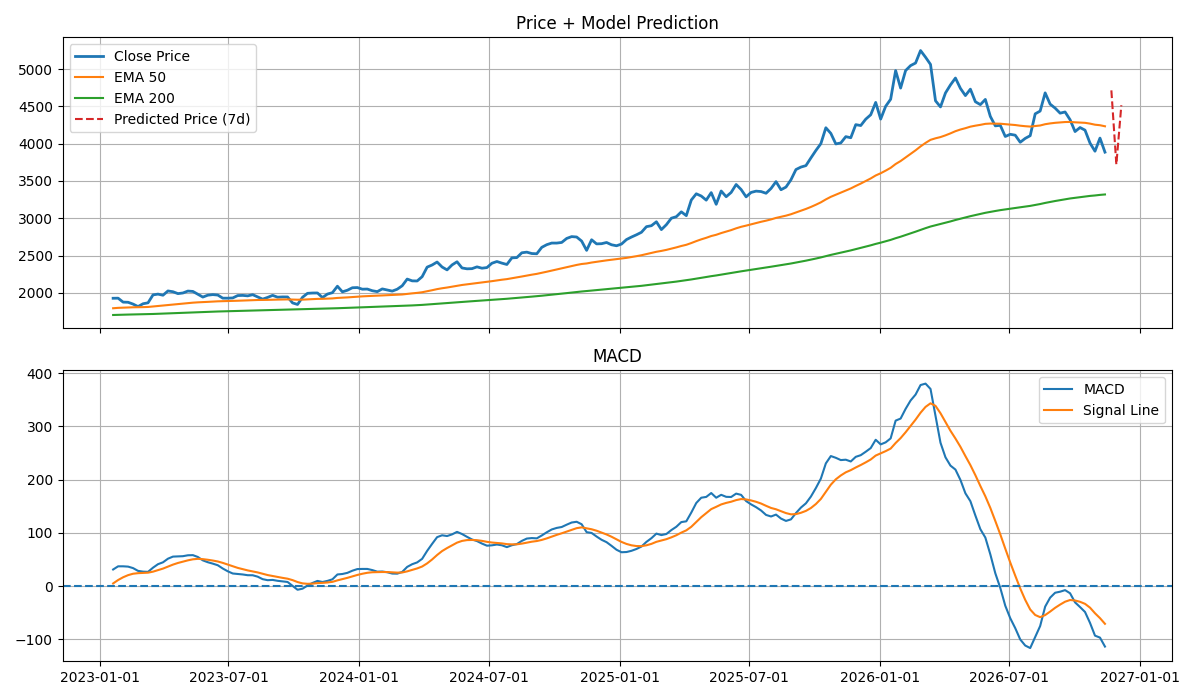

In [17]:

from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mplcursors
import matplotlib.dates as mdates

# ===== Predicted future dates =====
last_date = dates[-1]

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(weeks=1),
    periods=3,
    freq="1W"
)

# Last known close
last_close = close_plot.iloc[-1]

# Model predicted path
pred_path = y_scaler.inverse_transform(
    pred_scaled.reshape(1, -1)
)[0]

# ===== CREATE FIGURE =====
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True
)

# ---------------- PRICE PANEL ----------------
line_close, = ax1.plot(
    dates, close_plot, label="Close Price", linewidth=2
)

line_ema50, = ax1.plot(
    dates, ema50_plot, label="EMA 50"
)

line_ema200, = ax1.plot(
    dates, ema200_plot, label="EMA 200"
)

line_pred, = ax1.plot(
    future_dates, pred_path,
    "--", label="Predicted Price (7d)"
)

if long_signal:
    ax1.scatter(
        dates[-1], last_close,
        s=120, marker="^", label="Long Signal"
    )

ax1.set_title("Price + Model Prediction")
ax1.legend()
ax1.grid(True)

# ---------------- MACD PANEL ----------------
macd_plot = plot_data["MACD"]
signal_plot = plot_data["Signal_Line"]

line_macd, = ax2.plot(
    dates, macd_plot, label="MACD"
)

line_signal, = ax2.plot(
    dates, signal_plot, label="Signal Line"
)

ax2.axhline(0, linestyle="--")

ax2.set_title("MACD")
ax2.legend()
ax2.grid(True)

# ---------------- HOVER CURSORS ----------------

# Price panel
cursor_price = mplcursors.cursor(
    [line_close, line_ema50, line_ema200, line_pred],
    hover=True
)

@cursor_price.connect("add")
def on_add_price(sel):
    x, y = sel.target

    date = mdates.num2date(x).replace(tzinfo=None)

    sel.annotation.set_text(
        f"{sel.artist.get_label()}\n"
        f"Date: {date:%Y-%m-%d}\n"
        f"Price: {y:.2f}"
    )

    sel.annotation.get_bbox_patch().set(
        facecolor="white",
        alpha=0.9
    )

# MACD panel
cursor_macd = mplcursors.cursor(
    [line_macd, line_signal],
    hover=True
)

@cursor_macd.connect("add")
def on_add_macd(sel):
    x, y = sel.target

    date = mdates.num2date(x).replace(tzinfo=None)

    sel.annotation.set_text(
        f"{sel.artist.get_label()}\n"
        f"Date: {date:%Y-%m-%d}\n"
        f"Value: {y:.4f}"
    )

    sel.annotation.get_bbox_patch().set(
        facecolor="white",
        alpha=0.9
    )

# ---------------- DISPLAY ----------------
ax2.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m-%d")
)

plt.tight_layout()
plt.show()


In [39]:
%matplotlib inline
from google.colab import output
output.disable_custom_widget_manager()
import matplotlib.pyplot as plt
plt.close('all')